# Week 2: Preparing Loan Data for Machine Learning
**Fayz Liaqat | 16 October 2026**

This assignment takes a raw loan-application dataset through exploration,
cleaning, feature engineering, splitting, and preprocessing. The aim is to
produce clean numeric inputs and labels that a classification model can use.

**Final outputs:** `X_train`, `X_test`, `y_train`, and `y_test`.

I use camelCase for my variables and column names. The four final variable
names follow the assignment exactly. Library parameter names keep their
original spelling. There is no model training in this assignment.

## Step 0: Choose the dataset
I chose [Loan Predication on Kaggle](https://www.kaggle.com/datasets/ninzaami/loan-predication),
uploaded by amit parjapat. Kaggle lists this copy as CC0: Public Domain.
The actual downloaded CSV contains **614 rows and 13 columns**.
It has numeric inputs, text categories, and real missing values.

The target is `Loan_Status`: `Y` means approved and `N` means not approved.
This is **supervised binary classification** because each row already has
one of two known answers. The raw CSV is included in `data/loan_data.csv`.
The Kaggle description says 615 rows, but Pandas reads 614 data rows; the
file also contains a header row. I use the measured data-row count here.

Run the notebook from this project folder. No API key or internet connection
is needed because the dataset is included.

## Step 1: Load and explore the data
I first check the shape, data types, sample rows, summary statistics, and
target counts. I rename the columns to camelCase for readability, without
changing the original CSV. Four charts show the target balance, its
relationship with property area, the income distribution, and numeric
correlations. These observations describe this dataset, not causes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

projectDir = Path.cwd()
outputDir = projectDir / "outputs"
outputDir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110

loanData = pd.read_csv(projectDir / "data" / "loan_data.csv")
loanData = loanData.rename(columns={
    "Loan_ID": "loanId",
    "Gender": "gender",
    "Married": "married",
    "Dependents": "dependents",
    "Education": "education",
    "Self_Employed": "selfEmployed",
    "ApplicantIncome": "applicantIncome",
    "CoapplicantIncome": "coapplicantIncome",
    "LoanAmount": "loanAmount",
    "Loan_Amount_Term": "loanTerm",
    "Credit_History": "creditHistory",
    "Property_Area": "propertyArea",
    "Loan_Status": "loanStatus"
})

print("Rows and columns:", loanData.shape)
loanData.info()
display(loanData.head())
display(loanData.describe(include="all").T)
display(loanData["loanStatus"].value_counts().rename("count").to_frame())

Rows and columns: (614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loanId             614 non-null    object 
 1   gender             601 non-null    object 
 2   married            611 non-null    object 
 3   dependents         599 non-null    object 
 4   education          614 non-null    object 
 5   selfEmployed       582 non-null    object 
 6   applicantIncome    614 non-null    int64  
 7   coapplicantIncome  614 non-null    float64
 8   loanAmount         592 non-null    float64
 9   loanTerm           600 non-null    float64
 10  creditHistory      564 non-null    float64
 11  propertyArea       614 non-null    object 
 12  loanStatus         614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


,loanId,gender,married,dependents,education,selfEmployed,applicantIncome,coapplicantIncome,loanAmount,loanTerm,creditHistory,propertyArea,loanStatus
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loanId,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
selfEmployed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
applicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
coapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
loanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
loanTerm,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


,count
loanStatus,
Y,422
N,192


### Target distribution
The target countplot shows how many applications belong to each class.
More approved applications than rejected applications would mean the classes
are not evenly balanced. I keep that in mind when splitting the data.

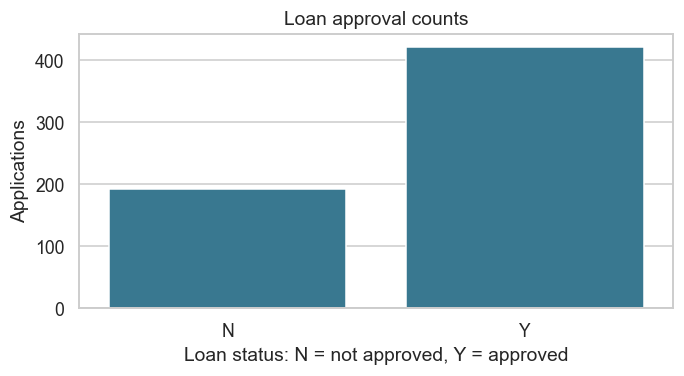

In [2]:
plt.figure(figsize=(6.4, 3.6))
sns.countplot(data=loanData, x="loanStatus", order=["N", "Y"], color="#2A7F9E")
plt.title("Loan approval counts")
plt.xlabel("Loan status: N = not approved, Y = approved")
plt.ylabel("Applications")
plt.tight_layout()
plt.savefig(outputDir / "target_distribution.png", dpi=180)
plt.show()
plt.close()

### Approval rate by property area
I compare the percentage approved in each area, rather than only comparing
counts. This accounts for the areas having different numbers of applications.

,approvedPercent
propertyArea,
Rural,61.45
Semiurban,76.82
Urban,65.84


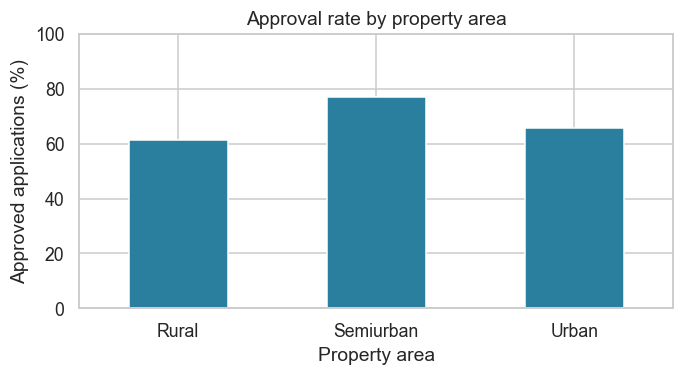

In [3]:
approvalByArea = pd.crosstab(
    loanData["propertyArea"], loanData["loanStatus"], normalize="index"
)["Y"] * 100
display(approvalByArea.round(2).rename("approvedPercent").to_frame())

plt.figure(figsize=(6.4, 3.6))
approvalByArea.plot(kind="bar", color="#2A7F9E", rot=0)
plt.title("Approval rate by property area")
plt.xlabel("Property area")
plt.ylabel("Approved applications (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(outputDir / "approval_by_area.png", dpi=180)
plt.show()
plt.close()

### Applicant income distribution
A histogram helps identify skew and unusually large values. I keep the
original values because a large income is not automatically a data error.
The chart uses the original income units from the dataset.

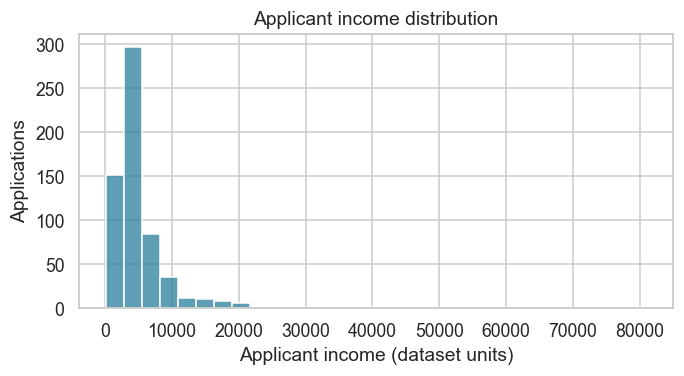

In [4]:
plt.figure(figsize=(6.4, 3.6))
sns.histplot(data=loanData, x="applicantIncome", bins=30, color="#2A7F9E")
plt.title("Applicant income distribution")
plt.xlabel("Applicant income (dataset units)")
plt.ylabel("Applications")
plt.tight_layout()
plt.savefig(outputDir / "income_histogram.png", dpi=180)
plt.show()
plt.close()

### Numeric correlation heatmap
I check linear relationships between the numeric columns. A correlation is
an association, not proof that one column causes another. Missing pairs are
excluded by Pandas when it calculates the correlations.

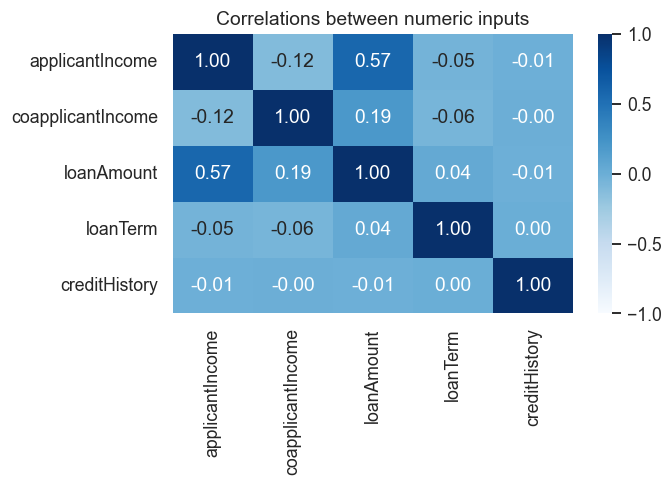

In [5]:
numericCorrelations = loanData.select_dtypes(include="number").corr()

plt.figure(figsize=(6.4, 4.6))
sns.heatmap(numericCorrelations, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlations between numeric inputs")
plt.tight_layout()
plt.savefig(outputDir / "correlation_heatmap.png", dpi=180)
plt.show()
plt.close()

### What I noticed
- There are 422 approved applications and 192 not approved, so the target is imbalanced.
- Semiurban applications have the highest approval rate in this file. This is a descriptive observation.
- Income is right-skewed: most values are lower, with a small number of very large values.
- Applicant income and loan amount have a positive correlation. This does not establish a cause.

I use the required full-dataset EDA for description only. The processing
rules below are fixed in advance; no test-set statistics will be used for
imputation, scaling, encoding, or feature selection.

## Step 2: Clean the data
I check and remove exact duplicate rows before splitting so repeated
records cannot appear on both sides. I count missing values, drop the
application ID, and keep the useful columns. There are no missing targets;
if there were, I would remove those rows because the answer is unknown.

**I do not fill missing inputs here.** The table records my decisions,
while the train-fitted pipelines in Step 6 perform the fills.

| Column | Problem | Action | Reason |
| --- | --- | --- | --- |
| `loanId` | Unique application identifier | Drop | Identifies a row rather than a useful pattern |
| `gender` | 13 missing text values | Training mode | Retains rows using an existing category |
| `married` | 3 missing text values | Training mode | Fills a small number of gaps with an existing category |
| `dependents` | 15 missing text values | Training mode | Keeps `3+` as a category without guessing an exact number |
| `selfEmployed` | 32 missing text values | Training mode | Keeps the column and uses its most common training value |
| `loanAmount` | 22 missing numeric values | Training median | Less affected by large amounts than the mean |
| `loanTerm` | 14 missing numeric values | Training median | Simple numeric fill required by this assignment |
| `creditHistory` | 50 missing numeric values | Training median | Follows the numeric rule; verify the learned median is a valid 0/1 value |

I keep all seven incomplete columns because their information can still
help a later model. Mode filling may overrepresent common categories.
Although `creditHistory` is stored numerically, it is a binary indicator.
The remaining columns need no fill in this file.

Exact duplicate rows: 0
Shape after duplicate removal: (614, 13)


,missingCount
loanId,0
gender,13
married,3
dependents,15
education,0
selfEmployed,32
applicantIncome,0
coapplicantIncome,0
loanAmount,22
loanTerm,14


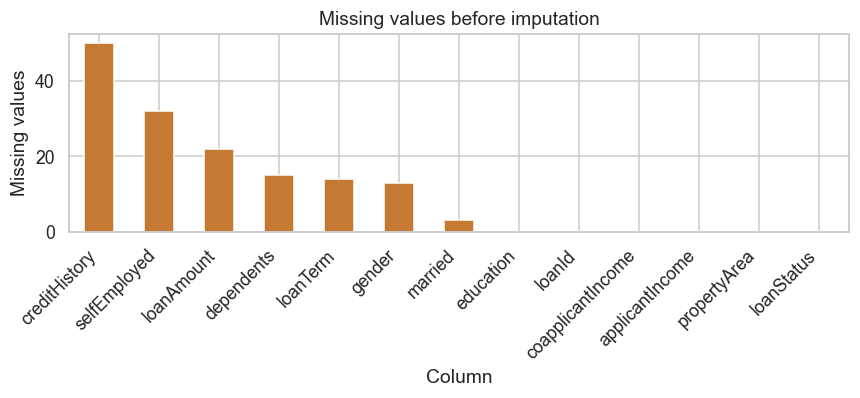

Rows with a missing target: 0
Shape after removing the ID: (614, 12)


In [6]:
duplicateCount = loanData.duplicated().sum()
print("Exact duplicate rows:", duplicateCount)
loanData = loanData.drop_duplicates().copy()
print("Shape after duplicate removal:", loanData.shape)

missingCounts = loanData.isna().sum()
display(missingCounts.rename("missingCount").to_frame())

plt.figure(figsize=(8, 3.8))
missingCounts.sort_values(ascending=False).plot(kind="bar", color="#C47A33")
plt.title("Missing values before imputation")
plt.xlabel("Column")
plt.ylabel("Missing values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(outputDir / "missing_values.png", dpi=180)
plt.show()
plt.close()

missingTargetCount = loanData["loanStatus"].isna().sum()
print("Rows with a missing target:", missingTargetCount)
loanData = loanData.dropna(subset=["loanStatus"]).copy()
loanData = loanData.drop(columns="loanId")
print("Shape after removing the ID:", loanData.shape)

## Step 3: Create two new features
- **`totalIncome`** adds applicant and co-applicant income. A household's
  combined income can give a later model a clearer view of available income.
- **`hasCoapplicantIncome`** is 1 when co-applicant income is greater than
  zero, otherwise 0. It separates applications with an income contribution
  from those without one. It does not prove whether a co-applicant exists.

Both source income columns are complete. I verify this before creating
the features. These are row-by-row rules that learn no statistics and use
no target values, so creating them before the split does not leak data.
The features are plausible additions; their predictive benefit is untested.

In [7]:
assert loanData[["applicantIncome", "coapplicantIncome"]].notna().all().all()

loanData["totalIncome"] = loanData["applicantIncome"] + loanData["coapplicantIncome"]
loanData["hasCoapplicantIncome"] = (loanData["coapplicantIncome"] > 0).astype(int)

display(loanData[[
    "applicantIncome", "coapplicantIncome", "totalIncome", "hasCoapplicantIncome"
]].head())

,applicantIncome,coapplicantIncome,totalIncome,hasCoapplicantIncome
0,5849,0.0,5849.0,0
1,4583,1508.0,6091.0,1
2,3000,0.0,3000.0,0
3,2583,2358.0,4941.0,1
4,6000,0.0,6000.0,0


## Step 4: Select the features and target
`X` contains the inputs and `y` contains the answer. I remove `loanStatus`
from the inputs and map `N` to 0 and `Y` to 1. This fixed mapping does not
need to learn anything from the data. The ID is already removed.

In [8]:
X = loanData.drop(columns="loanStatus")
y = loanData["loanStatus"].map({"N": 0, "Y": 1}).rename("loanStatus")
assert y.notna().all()

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Target mapping: 0 = not approved, 1 = approved")

Input shape: (614, 13)
Target shape: (614,)
Target mapping: 0 = not approved, 1 = approved


## Step 5: Make the train/test split
I use 80% for training and 20% for testing, with `random_state=42` so the
split is reproducible. `stratify=y` keeps similar class proportions in both
sets. The raw feature sets are kept separately for the train-only checks.

In [9]:
XTrainRaw, XTestRaw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training inputs:", XTrainRaw.shape, "Training target:", y_train.shape)
print("Test inputs:", XTestRaw.shape, "Test target:", y_test.shape)

classCounts = pd.DataFrame({
    "fullCount": y.value_counts(),
    "trainCount": y_train.value_counts(),
    "testCount": y_test.value_counts()
}).sort_index()
classProportions = pd.DataFrame({
    "fullPercent": y.value_counts(normalize=True) * 100,
    "trainPercent": y_train.value_counts(normalize=True) * 100,
    "testPercent": y_test.value_counts(normalize=True) * 100
}).sort_index().round(2)
display(classCounts)
display(classProportions)

Training inputs: (491, 13) Training target: (491,)
Test inputs: (123, 13) Test target: (123,)


,fullCount,trainCount,testCount
loanStatus,,,
0,192,154,38
1,422,337,85


,fullPercent,trainPercent,testPercent
loanStatus,,,
0,31.27,31.36,30.89
1,68.73,68.64,69.11


## Step 6: Preprocess using training data only
For numbers, I fill gaps with each training column's median, then use
`StandardScaler` to put the numeric features on comparable scales. It
subtracts the training mean and divides by the training standard deviation.
This can help models that depend on distances or feature magnitudes.

For text categories, I fill gaps with the training mode and use
`OneHotEncoder` to create 0/1 columns without inventing an order between
categories. `handle_unknown="ignore"` allows an unseen test category to
become all zeros in that category's encoded block. One-hot columns stay 0/1.

A `ColumnTransformer` combines the two pipelines. There is exactly one
fitting call: `fit_transform(XTrainRaw)`. Test data receives only
`transform(XTestRaw)` using the already learned settings. `y` stays 0/1.

In [10]:
numericColumns = XTrainRaw.select_dtypes(include="number").columns.tolist()
categoricalColumns = XTrainRaw.select_dtypes(include="object").columns.tolist()

numericPipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categoricalPipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numericPipeline, numericColumns),
    ("categorical", categoricalPipeline, categoricalColumns)
])

X_train = preprocessor.fit_transform(XTrainRaw)
X_test = preprocessor.transform(XTestRaw)

featureNames = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(X_train, columns=featureNames, index=XTrainRaw.index)
X_test = pd.DataFrame(X_test, columns=featureNames, index=XTestRaw.index)

print("Numeric columns:", numericColumns)
print("Categorical columns:", categoricalColumns)
display(X_train.head())

Numeric columns: ['applicantIncome', 'coapplicantIncome', 'loanAmount', 'loanTerm', 'creditHistory', 'totalIncome', 'hasCoapplicantIncome']
Categorical columns: ['gender', 'married', 'dependents', 'education', 'selfEmployed', 'propertyArea']


,numeric__applicantIncome,numeric__coapplicantIncome,numeric__loanAmount,numeric__loanTerm,numeric__creditHistory,numeric__totalIncome,numeric__hasCoapplicantIncome,categorical__gender_Female,categorical__gender_Male,categorical__married_No,...,categorical__dependents_1,categorical__dependents_2,categorical__dependents_3+,categorical__education_Graduate,categorical__education_Not Graduate,categorical__selfEmployed_No,categorical__selfEmployed_Yes,categorical__propertyArea_Rural,categorical__propertyArea_Semiurban,categorical__propertyArea_Urban
154,-0.352802,-0.563228,-1.131588,0.280691,0.397516,-0.575168,-1.096264,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
239,-0.343346,-0.563228,-0.592309,0.280691,0.397516,-0.566044,-1.096264,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
448,-0.339471,0.050405,0.040758,0.280691,-2.515623,-0.306544,0.912189,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
471,-0.445963,-0.024953,-0.393010,-2.486768,-2.515623,-0.440706,0.912189,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
273,-0.451078,0.234495,0.040758,0.280691,0.397516,-0.337505,0.912189,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


## Step 7: Check the final results
I check shapes, missing values, finite numbers, matching feature columns,
and alignment between each input row and its target. The train and test
indices must not overlap.

To check the fitted values, I compare the imputer's medians and modes
against the training data. I also check the scaler's sample count and
training means, and the encoder's learned categories. These checks support
the visible code: the test set is transformed, never fitted.

In [11]:
finalShapes = pd.DataFrame({
    "output": ["X_train", "X_test", "y_train", "y_test"],
    "shape": [X_train.shape, X_test.shape, y_train.shape, y_test.shape]
})
display(finalShapes)

missingValues = pd.Series({
    "X_train": X_train.isna().sum().sum(),
    "X_test": X_test.isna().sum().sum(),
    "y_train": y_train.isna().sum(),
    "y_test": y_test.isna().sum()
}, name="missingValues")
display(missingValues.to_frame())

assert missingValues.sum() == 0
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(XTrainRaw.index).isdisjoint(XTestRaw.index)
assert len(X_train) + len(X_test) == len(X)
print("All shape, missing-value, finite-value, and row-alignment checks passed.")

,output,shape
0,X_train,"(491, 22)"
1,X_test,"(123, 22)"
2,y_train,"(491,)"
3,y_test,"(123,)"


,missingValues
X_train,0
X_test,0
y_train,0
y_test,0


All shape, missing-value, finite-value, and row-alignment checks passed.


In [12]:
fittedNumeric = preprocessor.named_transformers_["numeric"]
fittedCategorical = preprocessor.named_transformers_["categorical"]
trainingMedians = XTrainRaw[numericColumns].median()
trainingModes = XTrainRaw[categoricalColumns].mode().iloc[0]
filledTrainingNumbers = XTrainRaw[numericColumns].fillna(trainingMedians)

np.testing.assert_allclose(
    fittedNumeric.named_steps["imputer"].statistics_, trainingMedians
)
assert np.array_equal(
    fittedCategorical.named_steps["imputer"].statistics_, trainingModes.to_numpy()
)
np.testing.assert_allclose(
    fittedNumeric.named_steps["scaler"].mean_, filledTrainingNumbers.mean()
)
assert fittedNumeric.named_steps["scaler"].n_samples_seen_ == len(XTrainRaw)
assert trainingMedians["creditHistory"] in [0, 1]

for columnIndex, columnName in enumerate(categoricalColumns):
    trainingCategories = sorted(
        XTrainRaw[columnName].fillna(trainingModes[columnName]).unique()
    )
    learnedCategories = fittedCategorical.named_steps["encoder"].categories_[columnIndex]
    assert np.array_equal(learnedCategories, trainingCategories)

print("Training medians, modes, scaler statistics, and encoder categories verified.")
print("The preprocessor was fitted on", len(XTrainRaw), "training rows only.")
print("The test data was processed with transform() only.")

Training medians, modes, scaler statistics, and encoder categories verified.
The preprocessor was fitted on 491 training rows only.
The test data was processed with transform() only.


## Save the four required outputs
I save the prepared inputs and targets as CSV files so they can be used
for the next assignment. Rows are written in matching order and without
a CSV index column. The four variables also remain available in memory.

In [13]:
X_train.to_csv(outputDir / "X_train.csv", index=False)
X_test.to_csv(outputDir / "X_test.csv", index=False)
y_train.to_csv(outputDir / "y_train.csv", index=False)
y_test.to_csv(outputDir / "y_test.csv", index=False)
print("Saved X_train.csv, X_test.csv, y_train.csv, and y_test.csv in outputs/.")

Saved X_train.csv, X_test.csv, y_train.csv, and y_test.csv in outputs/.


## Conclusion
The raw file is now split into clean numeric inputs and 0/1 targets.
The final input shapes are **491 x 22** for training and **123 x 22**
for testing. The target shapes are **(491,)** and **(123,)**.
No missing or infinite values remain. Seven numeric features were scaled,
and six categorical features became fifteen one-hot columns.

The main challenge was keeping the cleaning decisions separate from the
learned fill values. I learned that a dataset can be explored first, but
imputation, scaling, and category learning must use training data only.
I also kept `3+` dependents as a category and checked the actual CSV row
count instead of relying on the dataset description.

I have prepared the data, not trained a model. The added features have
not yet been tested for predictive benefit. Standard scaling does not
remove outliers or fix skew. This small historical dataset is suitable
for practice and does not establish suitability for lending decisions.

**Source:** [Kaggle: Loan Predication](https://www.kaggle.com/datasets/ninzaami/loan-predication)